<a href="https://colab.research.google.com/github/laraatanfoglio/DeepFake-Detection/blob/main/cupid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepFake Detection - Trends and Application for Computer Vision Exam

**Area:** T1, Multimedia Forensics (deepfake detection, AI-generated media identification)

**Starting point assigned:** Affatato, Mandelli, Cannas, Bestagini, Tubaro, *CUPID*, arXiv 2026 (submitted to IEEE)

---

## 1. Context

Deepfakes targeting a specific person (a *Person-of-Interest*, POI: politician, celebrity, executive) enable disinformation and fraud, including real cases in video calls. Because a POI is usually well documented, a detector can be built around genuine footage of that person.

Two families of POI detectors exist:
1. **POI-specific training:** one model per person, which needs a lot of footage of that person.
2. **General identity representation + reference set:** the encoder is trained on real videos of many subjects; the POI is enrolled only at inference with a few pristine videos, and a test video is scored by its similarity to them. CUPID belongs to this family, together with ID-Reveal and POI-Forensics.

## 2. Gaps assigned by the project

1. Exploit **temporal information**, not just single frames.
2. Combine video detection with **fake audio detection**.
3. Extend the method **beyond Person-of-Interest**.
4. Test **true videoconferencing compression** (WebRTC with H.264 and VP8), not only offline recompression.

## 3. CUPID

**CUPID** is a visual-only POI detector that:
- fits a 3D Morphable Model to each frame and unwraps the face into a **UV texture map**, where each face region always sits at the same position across identities, poses and expressions;
- trains a **Masked Autoencoder (ViT)** on these maps from **real videos only** (VoxCeleb2), with reconstruction, multi-layer identity-contrastive and perceptual losses;
- scores a test video by the **maximum cosine similarity** between its embeddings and those of 10 reference videos (10 frames each);
- produces **interpretability maps** showing which facial regions deviate from the POI's identity.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /content/drive/MyDrive/CUPID_project
%cd /content/drive/MyDrive/CUPID_project
!git clone https://github.com/polimi-ispl/CUPID.git
%cd CUPID
!apt-get -qq install -y ffmpeg fonts-dejavu-core
%pip install -e ".[demo]"
!mkdir -p /content/drive/MyDrive/CUPID_project/CUPID/downloads

Mounted at /content/drive
/content/drive/MyDrive/CUPID_project
fatal: destination path 'CUPID' already exists and is not an empty directory.
/content/drive/MyDrive/CUPID_project/CUPID
Selecting previously unselected package fonts-dejavu-mono.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-dejavu-mono_2.37-8_all.deb ...
Unpacking fonts-dejavu-mono (2.37-8) ...
Selecting previously unselected package fonts-dejavu-core.
Preparing to unpack .../fonts-dejavu-core_2.37-8_all.deb ...
Unpacking fonts-dejavu-core (2.37-8) ...
Setting up fonts-dejavu-mono (2.37-8) ...
Setting up fonts-dejavu-core (2.37-8) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
Obtaining file:///content/drive/MyDrive/CUPID_project/CUPID
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Cloning 

In [ ]:
%cd /content/drive/MyDrive/CUPID_project/CUPID/demo

# 1. Ripristina il file download.sh pulito dal repository git
!git checkout -- download.sh

# 2. Scarica i video senza cookie del browser
!COOKIES_FROM_BROWSER=none bash download.sh

/content/drive/MyDrive/CUPID_project/CUPID/demo
Found 10 URL(s) to download into 'downloads'.

==> Downloading: https://www.youtube.com/watch?v=usqUrdA_R3I
[youtube] Extracting URL: https://www.youtube.com/watch?v=usqUrdA_R3I
[youtube] usqUrdA_R3I: Downloading webpage
[youtube] usqUrdA_R3I: Downloading visionos player API JSON
ERROR: [youtube] usqUrdA_R3I: Sign in to confirm you’re not a bot. This helps protect our community. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
    FAILED: https://www.youtube.com/watch?v=usqUrdA_R3I

==> Downloading: https://www.youtube.com/watch?v=xpyrefzvTpI
[youtube] Extracting URL: https://www.youtube.com/watch?v=xpyrefzvTpI
[youtube] xpyrefzvTpI: Downloading webpage
[youtube] xpyrefzvTpI: Do

In [ ]:
import os
from pathlib import Path

# 1. Pulisci la cartella di cache corrotta/bloccata dal file 'lock'
!rm -rf /root/.cache/torch_extensions/py313_cu130/nvdiffrast_plugin

# 2. Fissa una cartella dedicata per le estensioni Torch e aggiungila a PYTHONPATH
ext_dir = Path("/content/torch_extensions")
plugin_dir = ext_dir / "nvdiffrast_plugin"
plugin_dir.mkdir(parents=True, exist_ok=True)

os.environ["TORCH_EXTENSIONS_DIR"] = str(ext_dir)
os.environ["PYTHONPATH"] = f"{plugin_dir}:" + os.environ.get("PYTHONPATH", "")

# 3. Spostati in demo/, prepara le clip mancanti e poi lancia quickstart.py
%cd /content/drive/MyDrive/CUPID_project/CUPID/demo
!bash prepare_clips.sh
!python quickstart.py

/content/drive/MyDrive/CUPID_project/CUPID/demo
Clearing old clips in 'clips'...

==> ref <- TIME - Leonardo_DiCaprio_Reveals_the_Stories_Behind_His_Most_Iconic_Movies [usqUrdA_R3I].mp4
    [00:00:08 -> 00:00:13] -> ref_1.mp4
    [00:00:22 -> 00:00:24] -> ref_2.mp4
    [00:00:36 -> 00:00:41] -> ref_3.mp4

==> ref <- Oscars - Leonardo_DiCaprio_winning_Best_Actor_88th_Oscars_2016 [xpyrefzvTpI].mp4
    [00:02:22 -> 00:02:26] -> ref_4.mp4
    [00:03:05 -> 00:03:10] -> ref_5.mp4
    [00:03:27 -> 00:03:33] -> ref_6.mp4

==> ref <- CBS_News - Leonardo_DiCaprio_commends_signing_of_Paris_Accords_as_reason_for_hope_2016 [IHkJzVx0Jd4].mp4
    [00:04:29 -> 00:04:32] -> ref_7.mp4
    [00:05:55 -> 00:06:00] -> ref_8.mp4

==> test_real <- TheEllenShow - Leonardo_DiCaprio_on_Wolf_of_Wall_Street_Jonah_Hill_Shark_Survival_Story_Full_Interview [lkUKu0NZhb4].mp4
    [00:05:54 -> 00:06:03] -> test_real_1.mp4

==> test_real <- Variety - Leonardo_DiCaprio_Jennifer_Lawrence_Actors_on_Actors [Q_cV9ciktoQ].mp4


{
  "reference_clips": [
    "ref_1.mp4",
    "ref_2.mp4",
    "ref_3.mp4",
    "ref_4.mp4",
    "ref_5.mp4",
    "ref_6.mp4",
    "ref_7.mp4",
    "ref_8.mp4"
  ],
  "num_reference_descriptors": 120,
  "frames_per_video": 15,
  "resolution": "native",
  "sampling": "equispaced",
  "auc": 0.9166666666666666,
  "margin": -0.0032168030738830566,
  "comparison": {
    "real": "test_real_2.mp4",
    "fake": "test_fake_2.mp4"
  },
  "results": [
    {
      "clip": "test_real_3.mp4",
      "label": "real",
      "score": 0.8902257084846497
    },
    {
      "clip": "test_real_1.mp4",
      "label": "real",
      "score": 0.8549095392227173
    },
    {
      "clip": "test_fake_3.mp4",
      "label": "fake",
      "score": 0.8051103949546814
    },
    {
      "clip": "test_real_2.mp4",
      "label": "real",
      "score": 0.8018935918807983
    },
    {
      "clip": "test_fake_4.mp4",
      "label": "fake",
      "score": 0.7914522886276245
    },
    {
      "clip": "test_fake_1.mp4",
 

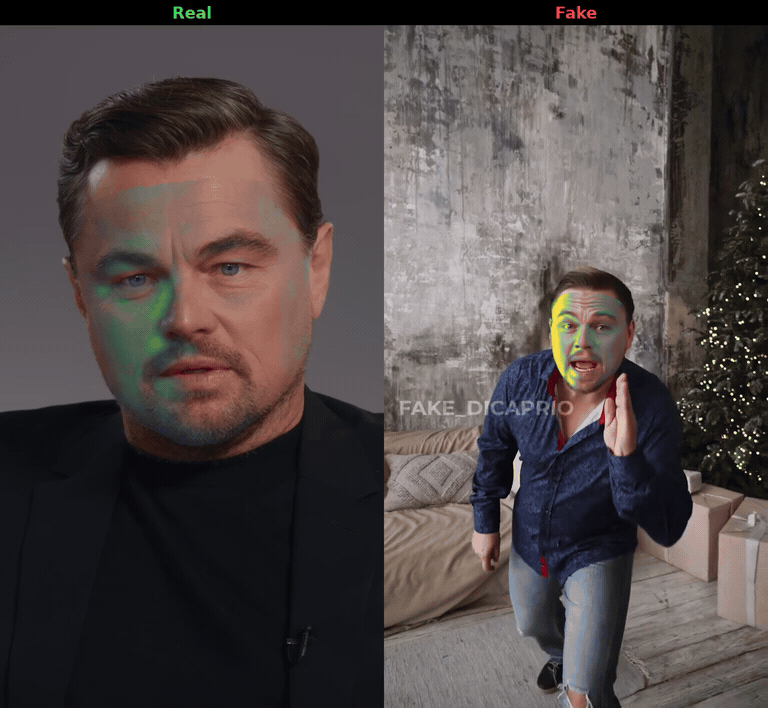

In [ ]:
import json
from IPython.display import Image, display

with open("/content/drive/MyDrive/CUPID_project/CUPID/demo/results/scores.json") as f:
    print(json.dumps(json.load(f), indent=2))

display(Image(filename="/content/drive/MyDrive/CUPID_project/CUPID/demo/results/comparison.gif"))

---

# Datasets Download

In [2]:
import os
import shutil
import zipfile
import tarfile
import requests
from pathlib import Path
from google.colab import userdata
from huggingface_hub import hf_hub_download, snapshot_download

# Disabilita la cache pesante di HF
os.environ["HF_HOME"] = "/tmp/hf_cache"
os.environ["HF_HUB_DISABLE_XET"] = "1"

try:
    hf_token = userdata.get("HF_TOKEN")
except Exception:
    print("Warning: HF_TOKEN non trovato nei segreti di Colab. Verranno usate richieste non autenticate.")
    hf_token = None

BASE_DIR = Path("/content/datasets")
DEEPSPEAK_DIR = BASE_DIR / "deepspeak"
FAKEAV_DIR = BASE_DIR / "fakeavceleb"
VOXCELEB_DIR = BASE_DIR / "voxceleb"

for d in [DEEPSPEAK_DIR, FAKEAV_DIR, VOXCELEB_DIR]:
    d.mkdir(parents=True, exist_ok=True)

In [3]:
print("=== 1. Scaricamento FakeAVCeleb ===")
fav_zip = hf_hub_download(
    repo_id="GianRota03/deepspeak_v2",
    filename="FakeAVCeleb_v1.2.zip",
    repo_type="dataset",
    token=hf_token,
    local_dir="/tmp/downloads"
)

print("Estrazione FakeAVCeleb...")
with zipfile.ZipFile(fav_zip, 'r') as zf:
    zf.extractall(FAKEAV_DIR)

os.remove(fav_zip)
shutil.rmtree("/tmp/hf_cache", ignore_errors=True)
print(f"FakeAVCeleb pronto in: {FAKEAV_DIR}")

=== 1. Scaricamento FakeAVCeleb ===


FakeAVCeleb_v1.2.zip: reconstructing file:   0%|          |  0.00B / 6.40GB            

FakeAVCeleb_v1.2.zip: downloading bytes:           |  0.00B            

Estrazione FakeAVCeleb...
FakeAVCeleb pronto in: /content/datasets/fakeavceleb


In [4]:
import shutil
from pathlib import Path
from collections import defaultdict
from datasets import load_dataset
from tqdm.auto import tqdm

FAKEAV_ROOT = Path("/content/datasets/fakeavceleb/FakeAVCeleb_v1.2")
VOXCELEB_DIR = Path("/content/datasets/voxceleb")

if VOXCELEB_DIR.exists():
    shutil.rmtree(VOXCELEB_DIR)
VOXCELEB_DIR.mkdir(parents=True, exist_ok=True)

# Estrae gli ID target (es. "id00773")
target_ids = {
    p.name.strip() for p in (FAKEAV_ROOT / "RealVideo-RealAudio").rglob("id*") if p.is_dir()
}
print(f"ID target in FakeAVCeleb: {len(target_ids)}")

VIDEOS_PER_SPEAKER = 25
TARGET_SPEAKERS_COUNT = 30   # 30 soggetti completi = 180 video salvati

ds = load_dataset(
    "blueskyheaven/voxceleb2-mp4-binary",
    split="train",
    streaming=True,
    token=hf_token
)

counts = defaultdict(int)
completed_speakers = set()
scanned = 0

pbar = tqdm(total=TARGET_SPEAKERS_COUNT * VIDEOS_PER_SPEAKER, desc="Video target salvati")

for row in ds:
    scanned += 1
    raw_spk = str(row["speaker_id"]).strip()
    # Normalizza nel caso nel dataset fosse un intero (es. 773 -> id00773)
    spk = raw_spk if raw_spk.startswith("id") else f"id{int(raw_spk):05d}"

    # Diagnostica immediata al primo elemento per verificare il formato
    if scanned == 1:
        print(f"Primo speaker letto dal stream: raw='{raw_spk}' -> normalizzato='{spk}'")

    if spk not in target_ids or spk in completed_speakers:
        if scanned % 500 == 0:
            pbar.set_postfix({"scansionati": scanned, "soggetti_ok": len(completed_speakers)})
        continue

    raw = row["video"]
    video_bytes = raw["bytes"] if isinstance(raw, dict) else raw
    orig_name = Path(str(row["file_name"])).name
    if not orig_name.endswith(".mp4"):
        orig_name += ".mp4"

    out_path = VOXCELEB_DIR / spk / f"{counts[spk]:02d}_{orig_name}"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "wb") as f:
        f.write(video_bytes)

    counts[spk] += 1
    pbar.update(1)
    pbar.set_postfix({"scansionati": scanned, "soggetti_ok": len(completed_speakers)})

    if counts[spk] >= VIDEOS_PER_SPEAKER:
        completed_speakers.add(spk)

    if len(completed_speakers) >= TARGET_SPEAKERS_COUNT:
        break

pbar.close()
print(f"\nCompletato! Soggetti pronti: {len(completed_speakers)} | Video salvati: {sum(counts.values())}")

ID target in FakeAVCeleb: 500


README.md:   0%|          | 0.00/412 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Video target salvati:   0%|          | 0/750 [00:00<?, ?it/s]

Primo speaker letto dal stream: raw='id06581' -> normalizzato='id06581'

Completato! Soggetti pronti: 30 | Video salvati: 771


In [5]:
import zipfile
from pathlib import Path
from huggingface_hub import hf_hub_download

REPO_ID = "faridlab/deepspeak_v2"
DEEPSPEAK_DIR = Path("/content/datasets/deepspeak")
DEEPSPEAK_DIR.mkdir(parents=True, exist_ok=True)

ALLOWED_EXTS = (".wav", ".flac", ".mp4", ".json", ".csv")

print("=== 2. Scaricamento annotazioni e subset DeepSpeak v2 ===")

# 1. Scarica sempre i file CSV delle annotazioni (leggerissimi, ~2.3 MB totali)
csv_files = ["annotations-fake.csv", "annotations-real.csv", "annotations-split-def.csv"]
for csv_name in csv_files:
    hf_hub_download(
        repo_id=REPO_ID,
        filename=csv_name,
        repo_type="dataset",
        local_dir=DEEPSPEAK_DIR,
        token=hf_token
    )

# 2. Scarica ed estrai solo i primi N shard .zip (ogni zip pesa ~4.5-6 GB)
SHARDS_TO_DOWNLOAD = ["deepspeak-v2-0.zip"]  # Aggiungi "deepspeak-v2-1.zip" solo se hai spazio su disco

for zip_name in SHARDS_TO_DOWNLOAD:
    print(f"Scaricamento {zip_name}...")
    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=zip_name,
        repo_type="dataset",
        local_dir="/tmp/deepspeak_zips",
        token=hf_token
    )

    print(f"Estrazione filtrata di {zip_name}...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            if not member.is_dir() and member.filename.endswith(ALLOWED_EXTS):
                zf.extract(member, path=DEEPSPEAK_DIR)

    # Elimina subito lo zip scaricato per liberare ~5 GB su Colab
    Path(zip_path).unlink(missing_ok=True)

print(f"DeepSpeak v2 pronto in: {DEEPSPEAK_DIR}")

=== 2. Scaricamento annotazioni e subset DeepSpeak v2 ===


annotations-fake.csv:   0%|          | 0.00/758k [00:00<?, ?B/s]

annotations-real.csv:   0%|          | 0.00/1.56M [00:00<?, ?B/s]

annotations-split-def.csv:   0%|          | 0.00/2.76k [00:00<?, ?B/s]

Scaricamento deepspeak-v2-0.zip...


deepspeak-v2-0.zip: reconstructing file:   0%|          |  0.00B / 4.49GB            

deepspeak-v2-0.zip: downloading bytes:           |  0.00B            

Estrazione filtrata di deepspeak-v2-0.zip...
DeepSpeak v2 pronto in: /content/datasets/deepspeak


In [6]:
import zipfile
import pandas as pd
from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download

REPO_ID = "faridlab/deepspeak_v2"
DS_DIR = Path("/content/datasets/deepspeak")

df_real = pd.read_csv(DS_DIR / "annotations-real.csv")
df_fake = pd.read_csv(DS_DIR / "annotations-fake.csv")

# Trova quali identità target hai già estratto nei fake
existing_fakes = {p.name for p in DS_DIR.rglob("*.mp4")}
target_ids = set(
    df_fake[df_fake["video-file"].isin(existing_fakes)]["identity-target"].unique()
)
needed_real_files = set(
    df_real[df_real["identity"].isin(target_ids)]["video-file"].unique()
)
print(f"Video reali da recuperare: {len(needed_real_files)}")

api = HfApi()
all_zips = sorted([
    f for f in api.list_repo_files(REPO_ID, repo_type="dataset", token=hf_token)
    if f.endswith(".zip")
])

# I video reali di solito si trovano negli ultimi shard (in ordine alfabetico 'real/' viene dopo 'facefusion/')
extracted = 0
for zip_name in reversed(all_zips):
    if extracted >= len(needed_real_files):
        break
    print(f"Controllo {zip_name}...")
    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=zip_name,
        repo_type="dataset",
        local_dir="/tmp/ds_tmp",
        token=hf_token
    )
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            fname = Path(member.filename).name
            if not member.is_dir() and fname in needed_real_files:
                zf.extract(member, path=DS_DIR)
                needed_real_files.remove(fname)
                extracted += 1

    Path(zip_path).unlink(missing_ok=True)
    print(f"Estratti finora: {extracted} video reali")

print("Fatto! Ora puoi lanciare l'inferenza su DeepSpeak v2.")

Video reali da recuperare: 5661
Controllo deepspeak-v2-9.zip...


deepspeak-v2-9.zip: reconstructing file:   0%|          |  0.00B / 4.66GB            

deepspeak-v2-9.zip: downloading bytes:           |  0.00B            

Estratti finora: 226 video reali
Controllo deepspeak-v2-8.zip...


deepspeak-v2-8.zip: reconstructing file:   0%|          |  0.00B / 5.39GB            

deepspeak-v2-8.zip: downloading bytes:           |  0.00B            

... (30 outputs left out)

Estratti finora: 2758 video reali
Controllo deepspeak-v2-2.zip...


deepspeak-v2-2.zip: reconstructing file:   0%|          |  0.00B / 5.29GB            

deepspeak-v2-2.zip: downloading bytes:           |  0.00B            

Estratti finora: 2968 video reali
Fatto! Ora puoi lanciare l'inferenza su DeepSpeak v2.


---

# Inferenza

In [ ]:
!apt-get update && apt-get install -y ffmpeg
!pip install -q ninja einops timm kornia scikit-learn pandas tqdm opencv-python-headless
!pip install -q --no-build-isolation git+https://github.com/NVlabs/nvdiffrast.git

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,132 kB]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [82.5 kB]
Get:9 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Hit:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:12 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,510 kB]
Get:13 http://security.ubuntu

In [ ]:
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score
from cupid.pipeline import CupidPipeline

# 1. Inizializza la pipeline ufficiale CUPID (10 frame uniformi per video come da paper)
pipe = CupidPipeline(device="cuda:0", frames_per_video=10)

def evaluate_dataset(json_path: str, name: str):
    with open(json_path, "r") as f:
        items = json.load(f)

    # Raggruppa per soggetto (POI): i 10 video di riferimento vengono estratti una sola volta per identità
    by_subject = {}
    for it in items:
        by_subject.setdefault(it["subject"], []).append(it)

    records = []
    for subj, subj_items in tqdm(by_subject.items(), desc=f"Valutazione {name}"):
        ref_videos = subj_items[0]["refs"]
        try:
            ref_set = pipe.extract_reference_set(ref_videos)
        except Exception as e:
            print(f"Errore reference per {subj}: {e}")
            continue

        for it in subj_items:
            try:
                # score_S alto = Real -> lo invertiamo (-score_S) perché label=1 è Fake
                score_S = float(pipe.score(ref_set["features"], it["query"]))
                records.append({
                    "subject": subj,
                    "query": it["query"],
                    "label": it["label"],
                    "score_S": score_S,
                    "fake_score": -score_S,
                })
            except Exception as e:
                print(f"Skip {it['query']}: {e}")

    df = pd.DataFrame(records)
    df.to_csv(f"/content/datasets/results_{name}.csv", index=False)

    def _metrics(y_true, y_score):
        auc = roc_auc_score(y_true, y_score) * 100.0
        fpr, tpr, thr = roc_curve(y_true, y_score)
        ba = 0.5 * (tpr + (1.0 - fpr))
        idx = int(np.argmax(ba))
        acc = accuracy_score(y_true, (y_score >= thr[idx]).astype(int)) * 100.0
        return auc, float(ba[idx]) * 100.0, acc

    # Tabella II: Dataset-level (soglia unica globale)
    ds_auc, ds_ba, ds_acc = _metrics(df["label"].values, df["fake_score"].values)

    # Tabella I: POI-level (media delle metriche calcolate per ciascuna identità)
    poi_m = [
        _metrics(g["label"].values, g["fake_score"].values)
        for _, g in df.groupby("subject") if g["label"].nunique() == 2
    ]
    poi_auc, poi_ba, poi_acc = np.mean(poi_m, axis=0)

    summary = pd.DataFrame([
        {
            "Dataset": name,
            "Setup": "POI-level (Tabella I)",
            "AUC (%)": round(float(poi_auc), 2),
            "Balanced Accuracy (%)": round(float(poi_ba), 2),
            "Accuracy (%)": round(float(poi_acc), 2),
        },
        {
            "Dataset": name,
            "Setup": "Dataset-level (Tabella II)",
            "AUC (%)": round(float(ds_auc), 2),
            "Balanced Accuracy (%)": round(float(ds_ba), 2),
            "Accuracy (%)": round(float(ds_acc), 2),
        },
    ])
    print(f"\n=== RISULTATI {name} ({len(df)} video valutati) ===")
    print(summary.to_string(index=False))
    print()
    return summary

# 2. Esegui la valutazione su entrambi i dataset
res_fav = evaluate_dataset("/content/datasets/fakeavceleb_paper.json", "FakeAVCeleb")
res_ds = evaluate_dataset("/content/datasets/deepspeak_paper.json", "DeepSpeak_v2")

Valutazione FakeAVCeleb:   0%|          | 0/31 [00:00<?, ?it/s]

create cuda ctx on device cuda:0

=== RISULTATI FakeAVCeleb (566 video valutati) ===
    Dataset                      Setup  AUC (%)  Balanced Accuracy (%)  Accuracy (%)
FakeAVCeleb      POI-level (Tabella I)    89.29                  91.15         91.15
FakeAVCeleb Dataset-level (Tabella II)    89.21                  82.86         82.86



Valutazione DeepSpeak_v2:   0%|          | 0/130 [00:00<?, ?it/s]


=== RISULTATI DeepSpeak_v2 (344 video valutati) ===
     Dataset                      Setup  AUC (%)  Balanced Accuracy (%)  Accuracy (%)
DeepSpeak_v2      POI-level (Tabella I)    87.59                  92.95         92.95
DeepSpeak_v2 Dataset-level (Tabella II)    82.31                  76.74         76.74



# MOTIF

In [ ]:
import os
import sys
import json
import hashlib
import av
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score

MOTIF_REPO = "/content/drive/MyDrive/MOTIF_project/MOTIF"
if MOTIF_REPO not in sys.path:
    sys.path.insert(0, MOTIF_REPO)

import motif.video
from motif.pipeline import MotifPipeline, MotifReferenceSet

OUT_DIR = Path("/content/drive/MyDrive/MOTIF_project/eval_results")
CACHE_DIR = Path("/content/motif_emb_cache")
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# 90 frame = 3.6s @ 25fps (sufficienti per le finestre L=75 del paper MOTIF)
MAX_FRAMES_PER_VIDEO = 90
TARGET_MAX_WIDTH = 640

pipe = MotifPipeline(device="cuda:0", batch_size=256)

# Individua il metodo corretto di CoeffExtractor una sola volta all'avvio
_extract_fn = None
for _m in ("extract", "extract_batch", "forward", "__call__"):
    if hasattr(pipe.extractor, _m) and callable(getattr(pipe.extractor, _m)):
        _extract_fn = getattr(pipe.extractor, _m)
        break

def ultra_fast_extract_video(extractor, path, batch_size=256):
    coeffs = []
    buffer = []
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        stream.thread_type = "AUTO"
        w, h = stream.width, stream.height
        scale = min(1.0, TARGET_MAX_WIDTH / max(w, h)) if max(w, h) > 0 else 1.0
        new_w = int(round(w * scale / 2) * 2)
        new_h = int(round(h * scale / 2) * 2)

        for idx, frame in enumerate(container.decode(stream)):
            if idx >= MAX_FRAMES_PER_VIDEO:
                break
            # Ridimensionamento diretto dentro libswscale (C/SIMD) prima di passare a NumPy/PyTorch
            if scale < 1.0:
                rgb = frame.to_ndarray(format="rgb24", width=new_w, height=new_h)
            else:
                rgb = frame.to_ndarray(format="rgb24")
            buffer.append(torch.from_numpy(rgb).permute(2, 0, 1))
            if len(buffer) == batch_size:
                coeffs.append(_extract_fn(torch.stack(buffer)))
                buffer.clear()
    if buffer:
        coeffs.append(_extract_fn(torch.stack(buffer)))
    if not coeffs:
        raise ValueError(f"Nessun frame estratto da {path}")
    return np.concatenate(coeffs, axis=0)

motif.video.extract_video = ultra_fast_extract_video


def get_cached_video_embeddings(video_path: str):
    key = hashlib.md5(video_path.encode("utf-8")).hexdigest()
    cache_file = CACHE_DIR / f"{key}.npz"

    if cache_file.exists():
        with np.load(cache_file) as data:
            return data["g"], data["m"]

    with torch.inference_mode():
        g_emb, m_emb = pipe.extract_video_embeddings(video_path)

    g_emb = np.asarray(g_emb, dtype=np.float32)
    m_emb = np.asarray(m_emb, dtype=np.float32)
    np.savez(cache_file, g=g_emb, m=m_emb)
    return g_emb, m_emb


def evaluate_motif_fast_ds(json_path: str, name: str):
    csv_path = OUT_DIR / f"motif_results_{name}.csv"
    with open(json_path, "r") as f:
        items = json.load(f)

    existing_records = []
    done_queries = set()
    if csv_path.exists():
        df_existing = pd.read_csv(csv_path)
        if len(df_existing) > 0:
            existing_records = df_existing.to_dict("records")
            done_queries = set(df_existing["query"].astype(str).tolist())
            print(f"[{name}] Riprendo da {len(done_queries)}/{len(items)} video già valutati.")

    remaining_items = [it for it in items if it["query"] not in done_queries]

    if remaining_items:
        by_subject = {}
        for it in remaining_items:
            by_subject.setdefault(it["subject"], []).append(it)

        records = list(existing_records)
        for subj, subj_items in tqdm(by_subject.items(), desc=f"[{name}] Valutazione per POI"):
            try:
                g_refs, m_refs = [], []
                for r in subj_items[0]["refs"]:
                    g, m = get_cached_video_embeddings(r)
                    g_refs.append(g)
                    m_refs.append(m)
                ref_set = MotifReferenceSet.enroll(g_refs, m_refs)
            except Exception as e:
                print(f"Errore reference {subj}: {e}")
                continue

            for it in subj_items:
                try:
                    g_q, m_q = get_cached_video_embeddings(it["query"])
                    g_score = float(ref_set.global_reference.calibrated_score(g_q))
                    m_score = float(ref_set.mouth_reference.calibrated_score(m_q))
                    fused = 0.5 * (g_score + m_score)
                    records.append({
                        "subject": subj,
                        "query": it["query"],
                        "label": it["label"],
                        "score_fused": fused,
                        "score_global": g_score,
                        "score_mouth": m_score,
                        "fake_score": -fused,
                        "fake_global": -g_score,
                        "fake_mouth": -m_score,
                    })
                except Exception as e:
                    print(f"Skip query {it['query']}: {e}")

            pd.DataFrame(records).to_csv(csv_path, index=False)

    df = pd.read_csv(csv_path)

    def _metrics(y_true, y_score):
        auc = roc_auc_score(y_true, y_score) * 100.0
        fpr, tpr, thr = roc_curve(y_true, y_score)
        ba = 0.5 * (tpr + (1.0 - fpr))
        idx = int(np.argmax(ba))
        acc = accuracy_score(y_true, (y_score >= thr[idx]).astype(int)) * 100.0
        return auc, float(ba[idx]) * 100.0, acc

    rows = []
    for branch_name, col in [
        ("Fused (Global+Mouth)", "fake_score"),
        ("Global only", "fake_global"),
        ("Mouth only", "fake_mouth"),
    ]:
        ds_auc, ds_ba, ds_acc = _metrics(df["label"].values, df[col].values)
        poi_m = [
            _metrics(g["label"].values, g[col].values)
            for _, g in df.groupby("subject")
            if g["label"].nunique() == 2
        ]
        poi_auc, poi_ba, poi_acc = np.mean(poi_m, axis=0)

        rows.append({
            "Dataset": name,
            "Branch": branch_name,
            "Setup": "POI-level",
            "AUC (%)": round(float(poi_auc), 2),
            "Balanced Accuracy (%)": round(float(poi_ba), 2),
            "Accuracy (%)": round(float(poi_acc), 2),
        })
        rows.append({
            "Dataset": name,
            "Branch": branch_name,
            "Setup": "Dataset-level",
            "AUC (%)": round(float(ds_auc), 2),
            "Balanced Accuracy (%)": round(float(ds_ba), 2),
            "Accuracy (%)": round(float(ds_acc), 2),
        })

    summary = pd.DataFrame(rows)
    print(f"\n=== RISULTATI MOTIF - {name} ({len(df)} video valutati) ===")
    print(summary.to_string(index=False))
    return summary

res_motif_ds = evaluate_motif_fast_ds("/content/datasets/deepspeak_paper.json", "DeepSpeak_v2")

[DeepSpeak_v2] Riprendo da 122/344 video già valutati.


[DeepSpeak_v2] Valutazione per POI:   0%|          | 0/90 [00:00<?, ?it/s]

Errore reference 489: CUDA out of memory. Tried to allocate 4.00 GiB. GPU 0 has a total capacity of 14.56 GiB of which 2.31 GiB is free. Including non-PyTorch memory, this process has 12.25 GiB memory in use. Of the allocated memory 6.74 GiB is allocated by PyTorch, and 5.37 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
Errore reference 381: CUDA out of memory. Tried to allocate 2.48 GiB. GPU 0 has a total capacity of 14.56 GiB of which 2.31 GiB is free. Including non-PyTorch memory, this process has 12.25 GiB memory in use. Of the allocated memory 6.96 GiB is allocated by PyTorch, and 5.15 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=e

# WavLM Base+

In [8]:
!pip install transformers torch accelerate datasets

In [17]:
feature_extractor = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")

# Sovrascriviamo qui la classe corretta WavLMAntiSpoofing con 13 layer per evitare conflitti
class WavLMAntiSpoofing(nn.Module):
    """WavLM Base+ backbone + Weighted Layer Sum + Attentive Statistics Pooling + Linear Head."""
    def __init__(self, model_name: str = "microsoft/wavlm-base-plus", freeze_backbone: bool = True):
        super().__init__()
        self.backbone = WavLMModel.from_pretrained(model_name, output_hidden_states=True)
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False

        # 13 layer totali (embedding iniziale + 12 transformer layers)
        num_layers = self.backbone.config.num_hidden_layers + 1
        hidden_dim = self.backbone.config.hidden_size

        self.layer_weights = nn.Parameter(torch.ones(num_layers) / num_layers)

        self.attention = nn.Sequential(
            nn.Conv1d(hidden_dim, 128, kernel_size=1),
            nn.Tanh(),
            nn.Conv1d(128, hidden_dim, kernel_size=1),
            nn.Softmax(dim=-1),
        )
        self.classifier = nn.Sequential(
            nn.BatchNorm1d(hidden_dim * 2),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim * 2, 1),
        )

    def forward(self, input_values: torch.Tensor) -> torch.Tensor:
        outputs = self.backbone(input_values)
        stacked = torch.stack(outputs.hidden_states, dim=0)  # [13, Batch, Time, Hidden]
        w = self.layer_weights[: stacked.size(0)]
        norm_weights = F.softmax(w, dim=0).view(-1, 1, 1, 1)
        x = (stacked * norm_weights).sum(dim=0).transpose(1, 2)  # [Batch, Hidden, Time]

        attn_w = self.attention(x)
        mean = torch.sum(x * attn_w, dim=-1)
        std = torch.sqrt(torch.clamp(torch.sum(((x - mean.unsqueeze(-1)) ** 2) * attn_w, dim=-1), min=1e-6))
        pooled = torch.cat([mean, std], dim=-1)  # [Batch, 1536]
        return self.classifier(pooled).squeeze(-1)

def run_audio_and_fusion(json_path: str, motif_csv_path: str, dataset_name: str, epochs: int = 8):
    with open(json_path, "r") as f:
        items = json.load(f)

    # Split rigoroso POI-disjoint (60% soggetti per train head, 40% soggetti per test)
    subjects = sorted(list({it["subject"] for it in items}))
    split_idx = int(0.6 * len(subjects))
    train_subjs = set(subjects[:split_idx])
    test_subjs = set(subjects[split_idx:])

    def _build_tensors(subset):
        wavs, labels, queries = [], [], []
        for it in tqdm(subset, desc=f"[{dataset_name}] Estrazione audio"):
            try:
                w = load_audio_16k(it["query"])
                wavs.append(w)
                labels.append(int(it["label"]))
                queries.append(it["query"])
            except Exception as e:
                print(f"Skip audio {it['query']}: {e}")
        inputs = feature_extractor(wavs, sampling_rate=SAMPLE_RATE, return_tensors="pt", padding=True)
        return inputs.input_values, torch.tensor(labels, dtype=torch.float32), queries

    train_items = [it for it in items if it["subject"] in train_subjs]
    test_items = [it for it in items if it["subject"] in test_subjs]

    X_train, y_train, _ = _build_tensors(train_items)
    X_test, y_test, test_queries = _build_tensors(test_items)

    model = WavLMAntiSpoofing(freeze_backbone=True).to(DEVICE)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-2
    )
    # Bilancia eventuali classi sbilanciate real/fake
    pos_weight = (y_train == 0).sum() / torch.clamp((y_train == 1).sum(), min=1)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))

    # Training rapido della sola classification head (~1 min su T4)
    batch_size = 32
    model.train()
    for ep in range(epochs):
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch_size):
            idx = perm[i : i + batch_size]
            xb = X_train[idx].to(DEVICE)
            yb = y_train[idx].to(DEVICE)
            optimizer.zero_grad()
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                logits = model(xb)
                loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

    # Inferenza sui soggetti di test
    model.eval()
    audio_logits = []
    with torch.inference_mode():
        for i in range(0, len(X_test), batch_size):
            xb = X_test[i : i + batch_size].to(DEVICE)
            audio_logits.append(model(xb).cpu().numpy())
    audio_scores = np.concatenate(audio_logits)

    df_audio = pd.DataFrame({"query": test_queries, "fake_audio": audio_scores})
    df_motif = pd.read_csv(motif_csv_path)
    df_merged = df_motif.merge(df_audio, on="query", how="inner")

    # Z-score calibration prima della Weighted Late Fusion
    for col in ["fake_global", "fake_mouth", "fake_audio"]:
        df_merged[f"{col}_z"] = (df_merged[col] - df_merged[col].mean()) / (df_merged[col].std() + 1e-8)

    # Weighted Late Fusion: S = w1*Global + w2*Mouth + w3*Audio
    df_merged["fake_multimodal"] = (
        0.45 * df_merged["fake_global_z"]
        + 0.20 * df_merged["fake_mouth_z"]
        + 0.35 * df_merged["fake_audio_z"]
    )

    def _poi_metrics(df_sub, col):
        aucs, bas, accs = [], [], []
        for _, g in df_sub.groupby("subject"):
            if g["label"].nunique() < 2:
                continue
            yt, ys = g["label"].values, g[col].values
            aucs.append(roc_auc_score(yt, ys) * 100.0)
            fpr, tpr, thr = roc_curve(yt, ys)
            ba = 0.5 * (tpr + (1.0 - fpr))
            idx = int(np.argmax(ba))
            bas.append(float(ba[idx]) * 100.0)
            accs.append(accuracy_score(yt, (ys >= thr[idx]).astype(int)) * 100.0)
        return np.mean(aucs), np.mean(bas), np.mean(accs)

    for label_name, col in [
        ("MOTIF Visual (Global+Mouth)", "fake_score"),
        ("Audio Only (WavLM Base+)", "fake_audio"),
        ("Multimodal Late Fusion", "fake_multimodal"),
    ]:
        auc, ba, acc = _poi_metrics(df_merged, col)
        print(f"[{dataset_name} - Test POI] {label_name:28s} -> AUC: {auc:.2f}% | BA: {ba:.2f}% | Acc: {acc:.2f}%")

    df_merged.to_csv(OUT_DIR / f"multimodal_results_{dataset_name}.csv", index=False)
    return df_merged

# Esecuzione immediata su FakeAVCeleb (che ha già motif_results_FakeAVCeleb.csv pronto su Drive)
df_fav_mm = run_audio_and_fusion(
    "/content/datasets/fakeavceleb_paper.json",
    str(OUT_DIR / "motif_results_FakeAVCeleb.csv"),
    "FakeAVCeleb",
)

[FakeAVCeleb] Estrazione audio:   0%|          | 0/378 [00:00<?, ?it/s]

[FakeAVCeleb] Estrazione audio:   0%|          | 0/188 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

[FakeAVCeleb - Test POI] MOTIF Visual (Global+Mouth)  -> AUC: 84.44% | BA: 87.71% | Acc: 87.71%
[FakeAVCeleb - Test POI] Audio Only (WavLM Base+)     -> AUC: 67.35% | BA: 83.56% | Acc: 83.56%
[FakeAVCeleb - Test POI] Multimodal Late Fusion       -> AUC: 77.14% | BA: 84.36% | Acc: 84.36%


Deepspeak Evaluation

In [18]:
def is_fake_audio_deepspeak(query_path: str, visual_label: int) -> int:
    """In DeepSpeak v2, i video fake che terminano con '-real.mp4' o i face-swap
    mantengono la traccia audio originale autentica; solo quelli con TTS sintetica hanno audio fake."""
    if visual_label == 0:
        return 0
    fname = os.path.basename(query_path).lower()
    tts_engines = ("playht", "speechify", "elevenlabs", "bark", "xtts", "tortoise", "fake")
    return 1 if any(t in fname for t in tts_engines) else 0


def run_audio_and_fusion_deepspeak(
    json_path: str,
    motif_csv_path: str,
    dataset_name: str = "DeepSpeak_v2",
    epochs: int = 8,
):
    with open(json_path, "r") as f:
        items = json.load(f)

    # Split rigoroso POI-disjoint (60% soggetti train, 40% soggetti test)
    subjects = sorted(list({it["subject"] for it in items}))
    split_idx = int(0.6 * len(subjects))
    train_subjs = set(subjects[:split_idx])
    test_subjs = set(subjects[split_idx:])

    def _build_tensors(subset):
        wavs, audio_labels, queries = [], [], []
        for it in tqdm(subset, desc=f"[{dataset_name}] Estrazione audio"):
            try:
                w = load_audio_16k(it["query"])
                wavs.append(w)
                audio_labels.append(is_fake_audio_deepspeak(it["query"], int(it["label"])))
                queries.append(it["query"])
            except Exception as e:
                print(f"Skip audio {it['query']}: {e}")
        inputs = feature_extractor(wavs, sampling_rate=SAMPLE_RATE, return_tensors="pt", padding=True)
        return inputs.input_values, torch.tensor(audio_labels, dtype=torch.float32), queries

    train_items = [it for it in items if it["subject"] in train_subjs]
    test_items = [it for it in items if it["subject"] in test_subjs]

    X_train, y_train, _ = _build_tensors(train_items)
    X_test, y_test_audio, test_queries = _build_tensors(test_items)
    print(f"[{dataset_name}] Train audio -> Real: {(y_train==0).sum().item()}, Fake TTS: {(y_train==1).sum().item()}")

    model = WavLMAntiSpoofing(freeze_backbone=True).to(DEVICE)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-2
    )
    pos_weight = (y_train == 0).sum() / torch.clamp((y_train == 1).sum(), min=1)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))

    batch_size = 32
    model.train()
    for ep in range(epochs):
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch_size):
            idx = perm[i : i + batch_size]
            xb = X_train[idx].to(DEVICE)
            yb = y_train[idx].to(DEVICE)
            optimizer.zero_grad()
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                logits = model(xb)
                loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

    model.eval()
    audio_logits = []
    with torch.inference_mode():
        for i in range(0, len(X_test), batch_size):
            xb = X_test[i : i + batch_size].to(DEVICE)
            audio_logits.append(model(xb).cpu().numpy())
    audio_scores = np.concatenate(audio_logits)

    df_audio = pd.DataFrame({
        "query": test_queries,
        "fake_audio": audio_scores,
        "audio_label": y_test_audio.numpy().astype(int),
    })
    df_motif = pd.read_csv(motif_csv_path)
    df_merged = df_motif.merge(df_audio, on="query", how="inner")

    # Z-score calibration prima della Weighted Late Fusion
    for col in ["fake_global", "fake_mouth", "fake_audio"]:
        df_merged[f"{col}_z"] = (df_merged[col] - df_merged[col].mean()) / (df_merged[col].std() + 1e-8)

    # Weighted Late Fusion multimodale (su label video/multimodale complessiva)
    df_merged["fake_multimodal"] = (
        0.50 * df_merged["fake_global_z"]
        + 0.25 * df_merged["fake_mouth_z"]
        + 0.25 * df_merged["fake_audio_z"]
    )

    def _poi_metrics(df_sub, score_col, label_col="label"):
        aucs, bas, accs = [], [], []
        for _, g in df_sub.groupby("subject"):
            if g[label_col].nunique() < 2:
                continue
            yt, ys = g[label_col].values, g[score_col].values
            aucs.append(roc_auc_score(yt, ys) * 100.0)
            fpr, tpr, thr = roc_curve(yt, ys)
            ba = 0.5 * (tpr + (1.0 - fpr))
            idx = int(np.argmax(ba))
            bas.append(float(ba[idx]) * 100.0)
            accs.append(accuracy_score(yt, (ys >= thr[idx]).astype(int)) * 100.0)
        return np.mean(aucs), np.mean(bas), np.mean(accs)

    # 1. Prestazioni del solo ramo audio sui deepfake vocali reali vs TTS
    a_auc, a_ba, a_acc = _poi_metrics(df_merged, "fake_audio", label_col="audio_label")
    print(f"[{dataset_name} - Audio Only (vs Audio Label)] -> AUC: {a_auc:.2f}% | BA: {a_ba:.2f}% | Acc: {a_acc:.2f}%")

    # 2. Confronto end-to-end (Visual MOTIF vs Multimodal Late Fusion) sulla detection complessiva
    for label_name, col in [
        ("MOTIF Visual (Global+Mouth)", "fake_score"),
        ("Multimodal Late Fusion", "fake_multimodal"),
    ]:
        auc, ba, acc = _poi_metrics(df_merged, col, label_col="label")
        print(f"[{dataset_name} - Overall POI] {label_name:28s} -> AUC: {auc:.2f}% | BA: {ba:.2f}% | Acc: {acc:.2f}%")

    df_merged.to_csv(OUT_DIR / f"multimodal_results_{dataset_name}.csv", index=False)
    return df_merged

# Esecuzione su DeepSpeak v2
df_ds_mm = run_audio_and_fusion_deepspeak(
    "/content/datasets/deepspeak_paper.json",
    str(OUT_DIR / "motif_results_DeepSpeak_v2.csv"),
    "DeepSpeak_v2",
)

[DeepSpeak_v2] Estrazione audio:   0%|          | 0/214 [00:00<?, ?it/s]

[DeepSpeak_v2] Estrazione audio:   0%|          | 0/130 [00:00<?, ?it/s]

[DeepSpeak_v2] Train audio -> Real: 180, Fake TTS: 34


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

[DeepSpeak_v2 - Audio Only (vs Audio Label)] -> AUC: 82.22% | BA: 91.11% | Acc: 88.89%
[DeepSpeak_v2 - Overall POI] MOTIF Visual (Global+Mouth)  -> AUC: 85.71% | BA: 92.86% | Acc: 92.86%
[DeepSpeak_v2 - Overall POI] Multimodal Late Fusion       -> AUC: 88.89% | BA: 93.65% | Acc: 93.65%
